In [9]:
import requests
import pandas as pd
import numpy as np
import time
from datetime import datetime, timezone

In [11]:
GAMMA_API = "https://gamma-api.polymarket.com"
DATA_API = "https://data-api.polymarket.com"

REQUEST_TIMEOUT = 30

In [13]:
all_markets = []

for offset in range(0, 1000, 100):
    response = requests.get(
        f"{GAMMA_API}/markets",
        params={
            "limit": 100,
            "offset": offset
        },
        timeout=REQUEST_TIMEOUT
    )

    response.raise_for_status()

    batch = response.json()
    all_markets.extend(batch)

    print(f"Offset {offset}: {len(batch)} markets")

    if len(batch) < 100:
        break

    time.sleep(0.2)

markets_df = pd.DataFrame(all_markets)

print("\nTotal markets:", len(markets_df))

Offset 0: 100 markets
Offset 100: 100 markets
Offset 200: 100 markets
Offset 300: 100 markets
Offset 400: 100 markets
Offset 500: 100 markets
Offset 600: 100 markets
Offset 700: 100 markets
Offset 800: 100 markets
Offset 900: 100 markets

Total markets: 1000


In [6]:
markets_df["volume"] = pd.to_numeric(
    markets_df["volume"],
    errors="coerce"
)

markets_df["liquidity"] = pd.to_numeric(
    markets_df["liquidity"],
    errors="coerce"
)

markets_df[
    [
        "id",
        "question",
        "volume",
        "liquidity",
        "active",
        "closed"
    ]
].sort_values(
    "volume",
    ascending=False
).head(50)

,id,question,volume,liquidity,active,closed
535,665374,Will the U.S. invade Iran before 2027?,6.735671e+07,6.322132e+05,True,False
75,561251,Will LeBron James win the 2028 US Presidential...,5.477944e+07,2.513384e+06,True,False
36,559687,Will Oprah Winfrey win the 2028 Democratic pre...,5.441914e+07,2.886002e+06,True,False
28,559679,Will Bernie Sanders win the 2028 Democratic pr...,5.274611e+07,8.989941e+05,True,False
33,559684,Will Chelsea Clinton win the 2028 Democratic p...,5.052585e+07,6.107815e+05,True,False
37,559688,Will Andrew Yang win the 2028 Democratic presi...,4.873301e+07,2.710172e+06,True,False
71,561247,Will Tim Walz win the 2028 US Presidential Ele...,4.472553e+07,2.369035e+06,True,False
31,559682,Will Hunter Biden win the 2028 Democratic pres...,4.449557e+07,1.160170e+06,True,False
118,561986,Will Byron Donalds win the 2028 Republican pre...,4.442092e+07,2.066092e+06,True,False
26,559677,Will Hillary Clinton win the 2028 Democratic p...,4.406061e+07,2.673994e+06,True,False


In [7]:
markets_df[
    [
        "id",
        "question",
        "volume",
        "liquidity",
        "active",
        "closed"
    ]
].sort_values(
    "volume",
    ascending=False
).iloc[50:150].reset_index(drop=True)

,id,question,volume,liquidity,active,closed
0,559657,Will Stephen A. Smith win the 2028 Democratic ...,2.303891e+07,1.923106e+06,True,False
1,562001,Will Steve Bannon win the 2028 Republican pres...,2.296649e+07,1.916785e+06,True,False
2,561256,Will Zohran Mamdani win the 2028 US Presidenti...,2.219753e+07,1.699393e+06,True,False
3,560317,Putin out as President of Russia by December 3...,2.183536e+07,8.778535e+05,True,False
4,561983,Will Greg Abbott win the 2028 Republican presi...,2.132934e+07,1.107723e+06,True,False
...,...,...,...,...,...,...
95,679042,Will Élisabeth Borne win the 2027 French presi...,5.446132e+06,6.063887e+05,True,False
96,616913,Will 11 Fed rate cuts happen in 2026?,5.268834e+06,5.417233e+05,True,False
97,679039,Will Michel Barnier win the 2027 French presid...,5.253712e+06,5.947708e+05,True,False
98,562803,Will the Republican Party control the House af...,5.012111e+06,6.218253e+05,True,False


In [8]:
markets_df[
    [
        "id",
        "question",
        "volume",
        "liquidity",
        "active",
        "closed"
    ]
].sort_values(
    "volume",
    ascending=False
).iloc[150:250].reset_index(drop=True)

,id,question,volume,liquidity,active,closed
0,601836,Will Augusto Cury win the 2026 Brazilian presi...,4.981968e+06,4.041551e+05,True,False
1,601832,Will Aldo Rebelo win the 2026 Brazilian presid...,4.956808e+06,2.272888e+06,True,False
2,616912,Will 10 Fed rate cuts happen in 2026?,4.951980e+06,5.228005e+05,True,False
3,637002,Will Donald Trump win the Nobel Peace Prize in...,4.896301e+06,3.606441e+05,True,False
4,679048,Will Manuel Bompard win the 2027 French presid...,4.826241e+06,5.848682e+05,True,False
...,...,...,...,...,...,...
95,628944,Will Betty Yee win the California Governor Ele...,1.748031e+06,3.511168e+05,True,False
96,608553,Will Khvicha Kvaratskhelia win the 2026 Ballon...,1.725206e+06,1.294445e+05,True,False
97,637910,Mitch McConnell steps down from Senate before ...,1.704326e+06,5.905624e+04,True,False
98,679021,Will Édouard Philippe win the 2027 French pres...,1.684073e+06,2.337262e+05,True,False


In [10]:
selected_ids = [
    665374,
    567621,
    663583,
    560317,
    616913,
    637002,
    608553,
    562803,
    628944,
    629040
]

selected_markets = markets_df[
    markets_df["id"].isin(selected_ids)
].copy()

selected_markets[
    ["id", "question", "conditionId", "volume", "liquidity"]
].sort_values("volume", ascending=False)

,id,question,conditionId,volume,liquidity


In [12]:
print(markets_df["id"].dtype)
print(markets_df["id"].head())

str
0    559651
1    559652
2    559653
3    559654
4    559655
Name: id, dtype: str


In [7]:
selected_ids = [
    "665374",
    "567621",
    "663583",
    "560317",
    "616913",
    "637002",
    "608553",
    "562803",
    "628944",
    "629040"
]

selected_markets = markets_df[
    markets_df["id"].astype(str).isin(selected_ids)
].copy()

print("Selected markets:", len(selected_markets))

selected_markets[
    ["id", "question", "conditionId", "volume", "liquidity"]
].sort_values(
    "volume",
    ascending=False
)

NameError: name 'markets_df' is not defined

In [6]:
test_market = selected_markets.iloc[0]

print("Market:", test_market["question"])
print("Condition ID:", test_market["conditionId"])

NameError: name 'selected_markets' is not defined

In [4]:
def get_market_trades(condition_id, max_trades=10000):
    all_trades = []

    for offset in range(0, max_trades, 100):
        response = requests.get(
            f"{DATA_API}/trades",
            params={
                "market": condition_id,
                "limit": 100,
                "offset": offset,
                "takerOnly": False
            },
            timeout=REQUEST_TIMEOUT
        )

        response.raise_for_status()

        batch = response.json()

        if not batch:
            break

        all_trades.extend(batch)

        print(
            f"Offset {offset}: "
            f"{len(batch)} trades"
        )

        if len(batch) < 100:
            break

        time.sleep(0.2)

    return pd.DataFrame(all_trades)

In [17]:
def get_market_stats(row):
    condition_id = row["conditionId"]

    try:
        trades_df = get_market_trades(
            condition_id,
            max_trades=10000
        )

        if trades_df.empty:
            return {
                "trade_count": 0,
                "unique_wallets": 0,
                "earliest_trade": pd.NaT,
                "latest_trade": pd.NaT,
                "duration_hours": 0
            }

        trades_df["datetime"] = pd.to_datetime(
            trades_df["timestamp"],
            unit="s",
            utc=True
        )

        earliest = trades_df["datetime"].min()
        latest = trades_df["datetime"].max()

        return {
            "trade_count": len(trades_df),
            "unique_wallets": trades_df["proxyWallet"].nunique(),
            "earliest_trade": earliest,
            "latest_trade": latest,
            "duration_hours": (
                (latest - earliest).total_seconds() / 3600
            )
        }

    except Exception as e:
        print(f"Error for {condition_id}: {e}")

        return {
            "trade_count": np.nan,
            "unique_wallets": np.nan,
            "earliest_trade": pd.NaT,
            "latest_trade": pd.NaT,
            "duration_hours": np.nan
        }

In [5]:
test_trades_df = get_market_trades(
    test_market["conditionId"],
    max_trades=10000
)

print("\nTotal trades:", len(test_trades_df))

NameError: name 'test_market' is not defined

In [18]:
test_trades_df["datetime"] = pd.to_datetime(
    test_trades_df["timestamp"],
    unit="s",
    utc=True
)

print("Unique wallets:", test_trades_df["proxyWallet"].nunique())
print("Earliest trade:", test_trades_df["datetime"].min())
print("Latest trade:", test_trades_df["datetime"].max())

duration = (
    test_trades_df["datetime"].max()
    - test_trades_df["datetime"].min()
)

print("Time span:", duration)

Unique wallets: 2358
Earliest trade: 2026-07-19 05:45:24+00:00
Latest trade: 2026-09-20 07:15:10+00:00
Time span: 63 days 01:29:46


In [19]:
if len(test_trades_df) >= 10000:
    print("⚠️ Hit the 10,000 trade collection limit")
else:
    print("✅ Collected the complete available history")

⚠️ Hit the 10,000 trade collection limit


In [20]:
# Basic trade statistics

print("Total trades:", len(test_trades_df))

print("\nUnique wallets:")
print(test_trades_df["proxyWallet"].nunique())

print("\nUnique assets:")
print(test_trades_df["asset"].nunique())

print("\nTrade sides:")
print(test_trades_df["side"].value_counts())

print("\nOutcomes:")
print(test_trades_df["outcome"].value_counts())

print("\nTrade size statistics:")
print(test_trades_df["size"].describe())

print("\nPrice statistics:")
print(test_trades_df["price"].describe())

Total trades: 10000

Unique wallets:
2358

Unique assets:
2

Trade sides:
side
BUY     5653
SELL    4347
Name: count, dtype: int64

Outcomes:
outcome
No     5763
Yes    4237
Name: count, dtype: int64

Trade size statistics:
count     10000.000000
mean        894.355591
std        5891.716241
min           0.010000
25%           6.530000
50%          22.329783
75%         232.917500
max      246630.490000
Name: size, dtype: float64

Price statistics:
count    10000.000000
mean         0.565309
std          0.421103
min          0.030000
25%          0.080000
50%          0.910000
75%          0.930000
max          0.970000
Name: price, dtype: float64


In [23]:
import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
# Trades per day

daily_trades = (
    test_trades_df
    .set_index("datetime")
    .resample("D")
    .size()
)

print(daily_trades)

datetime
2026-07-19 00:00:00+00:00    198
2026-07-20 00:00:00+00:00    265
2026-07-21 00:00:00+00:00    132
2026-07-22 00:00:00+00:00    207
2026-07-23 00:00:00+00:00    265
                            ... 
2026-09-16 00:00:00+00:00    117
2026-09-17 00:00:00+00:00    372
2026-09-18 00:00:00+00:00    212
2026-09-19 00:00:00+00:00     93
2026-09-20 00:00:00+00:00     13
Freq: D, Length: 64, dtype: int64


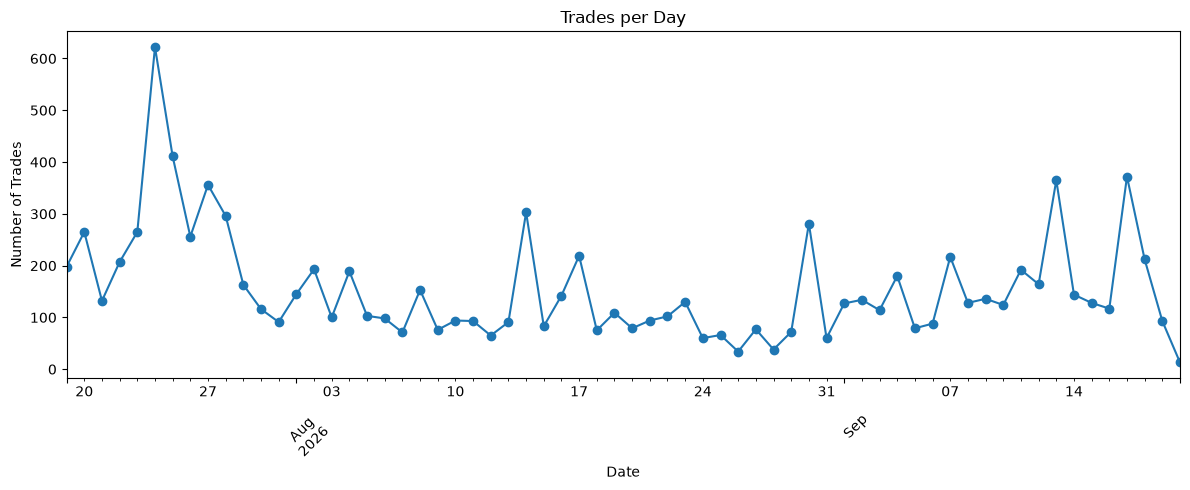

In [25]:
daily_trades.plot(
    figsize=(12, 5),
    marker="o"
)

plt.title("Trades per Day")
plt.xlabel("Date")
plt.ylabel("Number of Trades")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

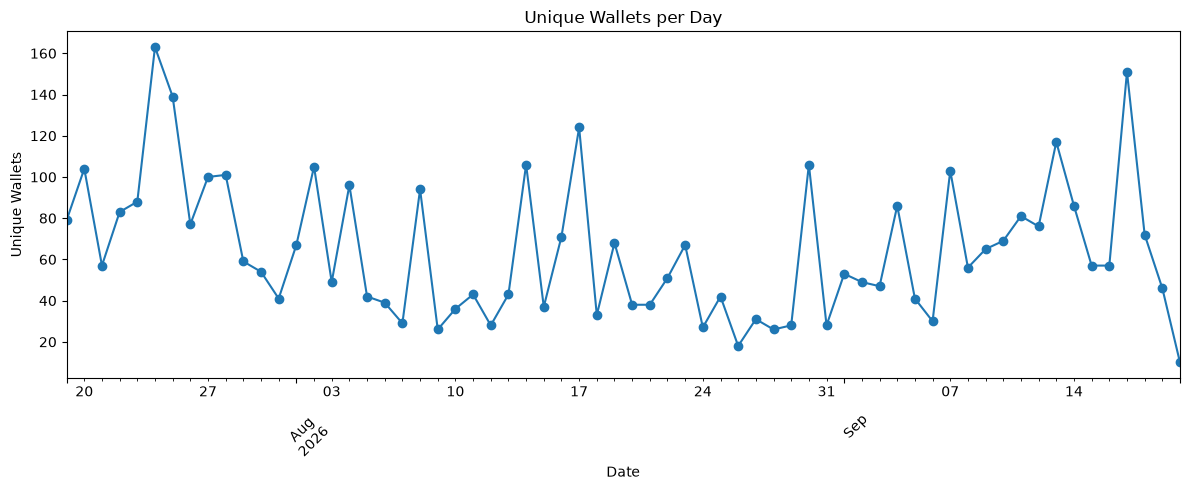

In [27]:
daily_wallets = (
    test_trades_df
    .set_index("datetime")["proxyWallet"]
    .resample("D")
    .nunique()
)

daily_wallets.plot(
    figsize=(12, 5),
    marker="o"
)

plt.title("Unique Wallets per Day")
plt.xlabel("Date")
plt.ylabel("Unique Wallets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
wallet_trade_counts = (
    test_trades_df["proxyWallet"]
    .value_counts()
)

print(wallet_trade_counts.describe())

count    2358.000000
mean        4.240882
std        25.717330
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max       958.000000
Name: count, dtype: float64


In [29]:
print("Wallets with 1 trade:",
      (wallet_trade_counts == 1).sum())

print("Wallets with 2-5 trades:",
      ((wallet_trade_counts >= 2) & (wallet_trade_counts <= 5)).sum())

print("Wallets with 10+ trades:",
      (wallet_trade_counts >= 10).sum())

print("Wallets with 50+ trades:",
      (wallet_trade_counts >= 50).sum())

Wallets with 1 trade: 1223
Wallets with 2-5 trades: 930
Wallets with 10+ trades: 134
Wallets with 50+ trades: 23


In [30]:
top_wallets = wallet_trade_counts.head(20)

print(top_wallets)

proxyWallet
0xb886580698ede4b18de3e446b2d8da8bcedd81b3    958
0xab19716584931d81cd9e7763402673a64baa4876    552
0xa58d4f278d7953cd38eeb929f7e242bfc7c0b9b8    335
0x8afa03dd6974e44d00c4d14dcccb00c0ddf6adb6    201
0xd7eee5e918dc59fa32386a4ad8a89655946e9597    165
0xe23b29408015a53249709a4e8331f9358c89f147    151
0xa6d9b55a6a3a54a9d50ca94c64f00af69c50fd2f    105
0x9d84ce0306f8551e02efef1680475fc0f1dc1344    105
0x9c2617462567859fcf5764e03b9a687ebca274bc    103
0xc02147dee42356b7a4edbb1c35ac4ffa95f61fa8     91
0xfb4defb359e998ade4694a5326b377ed1780ef35     87
0x10a7268e8318af0d229b5fee65ecdc52a75e8652     84
0xf1ef8705e9f63c790c6fffd6329aea7011718cd6     83
0xeed8c2be411025120fb511ea2332dd0a1f6135f0     68
0x919a9a3f3fb9265560703cf6fe3b38567f3b87b9     68
0xcc2982e3fbbcaf9af9fa373fa3ae392fd9457774     61
0x21d0c129deb8a7f7e1569045200d20e23862ce91     60
0x3876a4840f46a1329179a34442d27db8642e4802     58
0xa61ef8773ec2e821962306ca87d4b57e39ff0abd     58
0xc87ae1463755dfd6412843f6275cccf2ca09

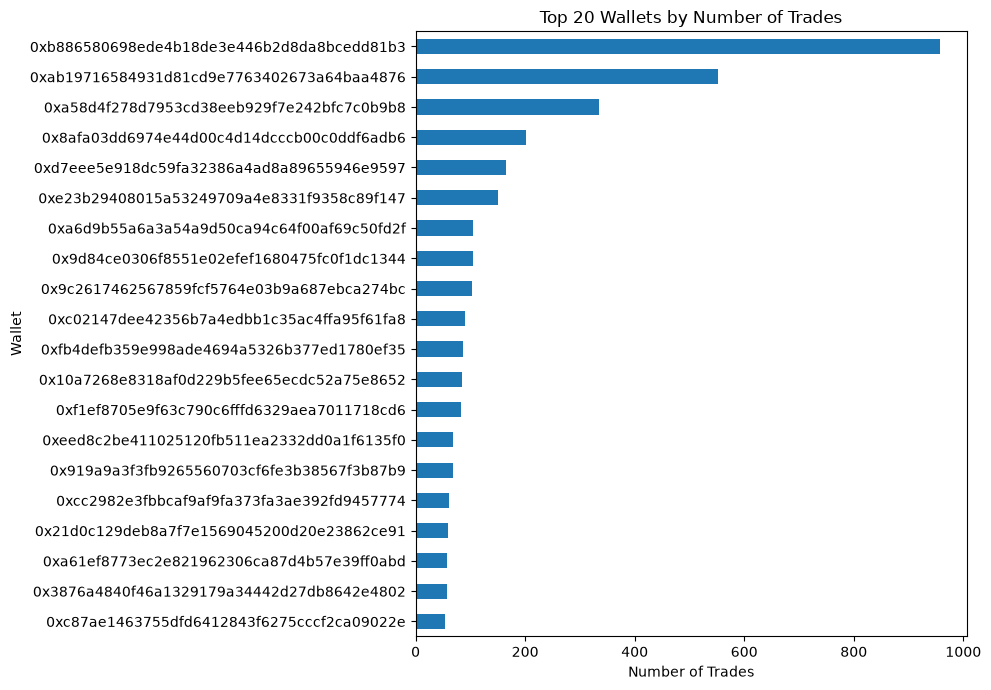

In [31]:
top_wallets.sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title("Top 20 Wallets by Number of Trades")
plt.xlabel("Number of Trades")
plt.ylabel("Wallet")
plt.tight_layout()
plt.show()

In [32]:
top_wallet = wallet_trade_counts.idxmax()

In [33]:
top_wallet_trades = test_trades_df[
    test_trades_df["proxyWallet"] == top_wallet
].sort_values("datetime")

top_wallet_trades[
    [
        "datetime",
        "side",
        "outcome",
        "price",
        "size",
        "asset"
    ]
].head(20)

,datetime,side,outcome,price,size,asset
9100,2026-07-23 12:43:36+00:00,BUY,Yes,0.08,5532.51,3509777698529173293870378932947630934718443462...
9098,2026-07-23 12:45:22+00:00,BUY,Yes,0.08,5.78,3509777698529173293870378932947630934718443462...
9096,2026-07-23 12:46:04+00:00,BUY,Yes,0.08,5.01,3509777698529173293870378932947630934718443462...
9092,2026-07-23 13:20:36+00:00,BUY,Yes,0.08,2.99,3509777698529173293870378932947630934718443462...
9090,2026-07-23 13:29:40+00:00,BUY,Yes,0.08,7.78,3509777698529173293870378932947630934718443462...
9084,2026-07-23 13:48:21+00:00,BUY,Yes,0.08,5.25,3509777698529173293870378932947630934718443462...
9082,2026-07-23 13:49:46+00:00,BUY,Yes,0.08,8.04,3509777698529173293870378932947630934718443462...
9080,2026-07-23 13:52:27+00:00,BUY,Yes,0.08,8.97,3509777698529173293870378932947630934718443462...
9070,2026-07-23 14:31:10+00:00,BUY,Yes,0.08,5.51,3509777698529173293870378932947630934718443462...
9068,2026-07-23 14:32:39+00:00,BUY,Yes,0.08,145.33,3509777698529173293870378932947630934718443462...


In [34]:
print(top_wallet_trades["side"].value_counts())
print()
print(top_wallet_trades["outcome"].value_counts())

side
BUY     632
SELL    326
Name: count, dtype: int64

outcome
Yes    958
Name: count, dtype: int64


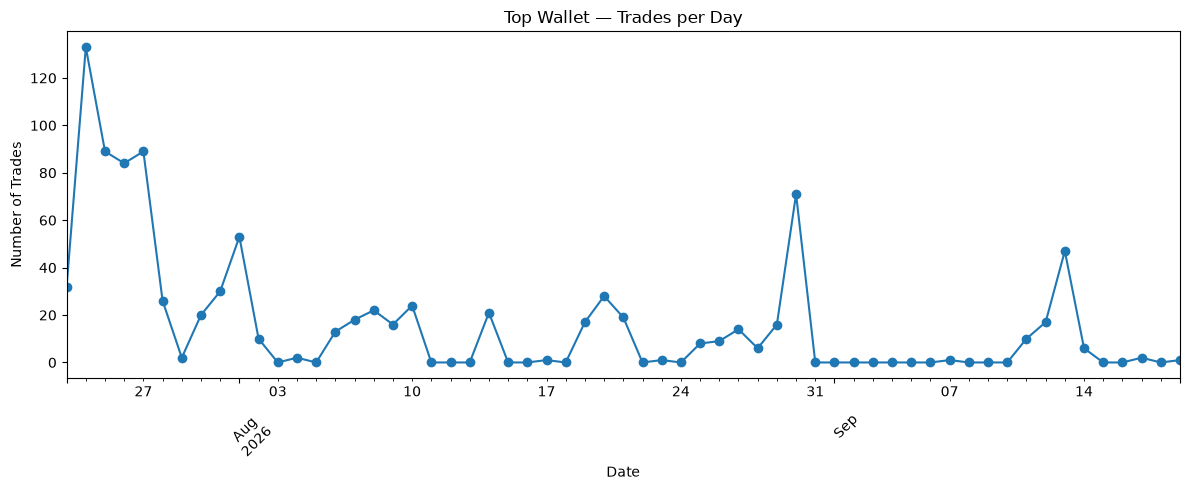

In [35]:
top_wallet_trades = top_wallet_trades.copy()

top_wallet_trades["datetime"] = pd.to_datetime(
    top_wallet_trades["timestamp"],
    unit="s",
    utc=True
)

daily_top_wallet = (
    top_wallet_trades
    .set_index("datetime")
    .resample("D")
    .size()
)

daily_top_wallet.plot(
    figsize=(12, 5),
    marker="o"
)

plt.title("Top Wallet — Trades per Day")
plt.xlabel("Date")
plt.ylabel("Number of Trades")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

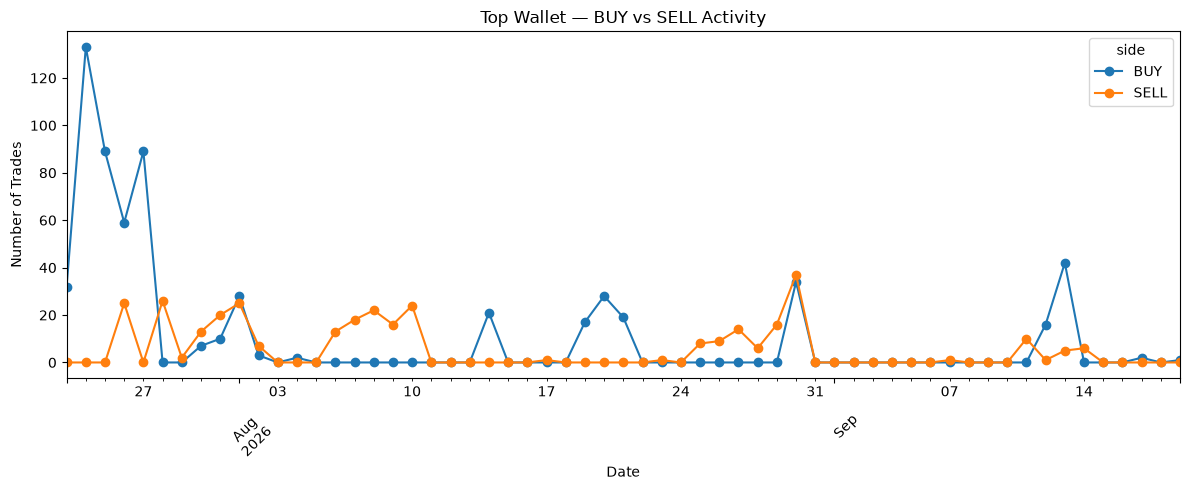

In [36]:
daily_side = (
    top_wallet_trades
    .set_index("datetime")
    .groupby("side")
    .resample("D")
    .size()
    .unstack(level=0)
    .fillna(0)
)

daily_side.plot(
    figsize=(12, 5),
    marker="o"
)

plt.title("Top Wallet — BUY vs SELL Activity")
plt.xlabel("Date")
plt.ylabel("Number of Trades")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [37]:
active_wallets = wallet_trade_counts[
    wallet_trade_counts >= 20
].index

print("Wallets with 20+ trades:", len(active_wallets))

wallet_a = active_wallets[0]
wallet_b = active_wallets[1]

print("Wallet A:", wallet_a)
print("Trades:", wallet_trade_counts[wallet_a])

print("\nWallet B:", wallet_b)
print("Trades:", wallet_trade_counts[wallet_b])

Wallets with 20+ trades: 72
Wallet A: 0xb886580698ede4b18de3e446b2d8da8bcedd81b3
Trades: 958

Wallet B: 0xab19716584931d81cd9e7763402673a64baa4876
Trades: 552


In [38]:
wallet_a_trades = (
    test_trades_df[
        test_trades_df["proxyWallet"] == wallet_a
    ]
    .sort_values("datetime")
)

wallet_b_trades = (
    test_trades_df[
        test_trades_df["proxyWallet"] == wallet_b
    ]
    .sort_values("datetime")
)

In [39]:
print("WALLET A")
display(
    wallet_a_trades[
        ["datetime", "side", "outcome", "price", "size"]
    ].head(20)
)

print("\nWALLET B")
display(
    wallet_b_trades[
        ["datetime", "side", "outcome", "price", "size"]
    ].head(20)
)

WALLET A


,datetime,side,outcome,price,size
9100,2026-07-23 12:43:36+00:00,BUY,Yes,0.08,5532.51
9098,2026-07-23 12:45:22+00:00,BUY,Yes,0.08,5.78
9096,2026-07-23 12:46:04+00:00,BUY,Yes,0.08,5.01
9092,2026-07-23 13:20:36+00:00,BUY,Yes,0.08,2.99
9090,2026-07-23 13:29:40+00:00,BUY,Yes,0.08,7.78
9084,2026-07-23 13:48:21+00:00,BUY,Yes,0.08,5.25
9082,2026-07-23 13:49:46+00:00,BUY,Yes,0.08,8.04
9080,2026-07-23 13:52:27+00:00,BUY,Yes,0.08,8.97
9070,2026-07-23 14:31:10+00:00,BUY,Yes,0.08,5.51
9068,2026-07-23 14:32:39+00:00,BUY,Yes,0.08,145.33



WALLET B


,datetime,side,outcome,price,size
9991,2026-07-19 06:46:10+00:00,SELL,Yes,0.1,587.039
9987,2026-07-19 07:06:52+00:00,SELL,Yes,0.1,10.000
9985,2026-07-19 07:27:06+00:00,SELL,Yes,0.1,398.000
9983,2026-07-19 08:07:19+00:00,SELL,Yes,0.1,10.000
9886,2026-07-19 14:40:52+00:00,SELL,Yes,0.1,2490.479
9877,2026-07-19 15:21:36+00:00,SELL,Yes,0.1,20.000
9875,2026-07-19 15:28:09+00:00,SELL,Yes,0.1,33.830
9873,2026-07-19 15:38:09+00:00,SELL,Yes,0.1,500.000
9871,2026-07-19 16:11:04+00:00,SELL,Yes,0.1,10.000
9869,2026-07-19 16:15:51+00:00,SELL,Yes,0.1,500.000


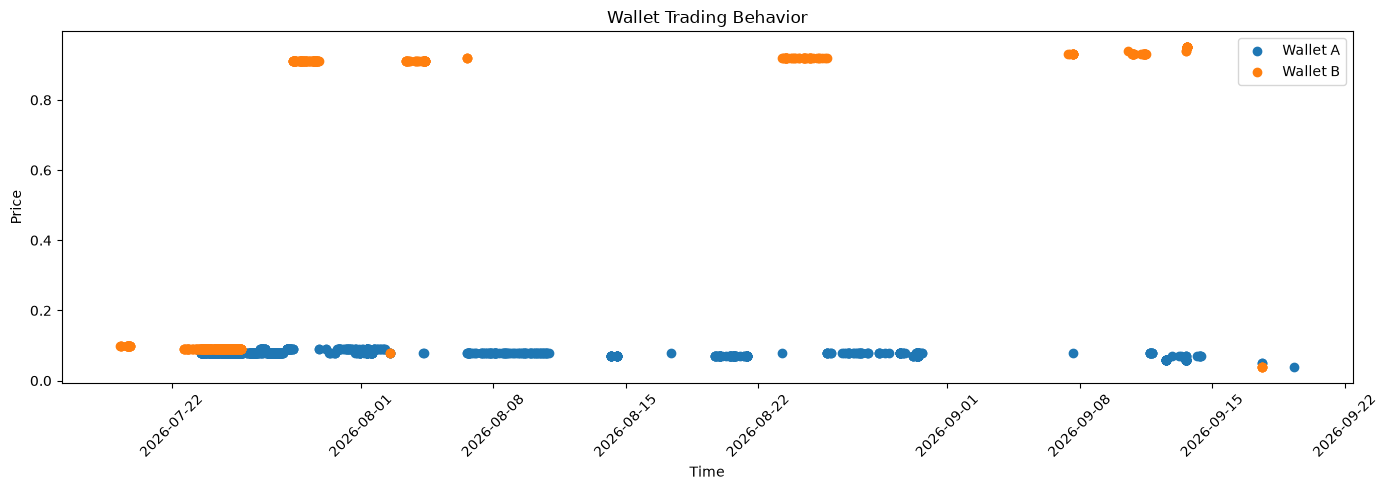

In [40]:
plt.figure(figsize=(14, 5))

plt.scatter(
    wallet_a_trades["datetime"],
    wallet_a_trades["price"],
    label="Wallet A"
)

plt.scatter(
    wallet_b_trades["datetime"],
    wallet_b_trades["price"],
    label="Wallet B"
)

plt.xlabel("Time")
plt.ylabel("Price")
plt.title("Wallet Trading Behavior")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [41]:
a_times = wallet_a_trades["datetime"].sort_values().tolist()
b_times = wallet_b_trades["datetime"].sort_values().tolist()

time_differences = []

for a_time in a_times:
    differences = [
        abs((a_time - b_time).total_seconds())
        for b_time in b_times
    ]

    time_differences.append(min(differences))

print("Average nearest-trade time difference:",
      np.mean(time_differences),
      "seconds")

print("Median nearest-trade time difference:",
      np.median(time_differences),
      "seconds")

Average nearest-trade time difference: 118597.71711899791 seconds
Median nearest-trade time difference: 74775.5 seconds


In [42]:
def nearest_time_difference(wallet_a, wallet_b, trades_df):
    a_times = (
        trades_df[trades_df["proxyWallet"] == wallet_a]["datetime"]
        .sort_values()
        .tolist()
    )

    b_times = (
        trades_df[trades_df["proxyWallet"] == wallet_b]["datetime"]
        .sort_values()
        .tolist()
    )

    if not a_times or not b_times:
        return np.nan

    differences = []

    for a_time in a_times:
        min_diff = min(
            abs((a_time - b_time).total_seconds())
            for b_time in b_times
        )
        differences.append(min_diff)

    return np.median(differences)

In [43]:
active_wallets = wallet_trade_counts[
    wallet_trade_counts >= 20
].index[:10]

results = []

for i in range(len(active_wallets)):
    for j in range(i + 1, len(active_wallets)):
        wallet_a = active_wallets[i]
        wallet_b = active_wallets[j]

        median_diff = nearest_time_difference(
            wallet_a,
            wallet_b,
            test_trades_df
        )

        results.append({
            "wallet_a": wallet_a,
            "wallet_b": wallet_b,
            "median_time_diff_seconds": median_diff
        })

pair_similarity_df = pd.DataFrame(results)

pair_similarity_df["median_time_diff_hours"] = (
    pair_similarity_df["median_time_diff_seconds"] / 3600
)

pair_similarity_df.sort_values(
    "median_time_diff_seconds"
).head(10)

,wallet_a,wallet_b,median_time_diff_seconds,median_time_diff_hours
37,0xe23b29408015a53249709a4e8331f9358c89f147,0x9c2617462567859fcf5764e03b9a687ebca274bc,696.0,0.193333
44,0x9c2617462567859fcf5764e03b9a687ebca274bc,0xc02147dee42356b7a4edbb1c35ac4ffa95f61fa8,23419.0,6.505278
38,0xe23b29408015a53249709a4e8331f9358c89f147,0xc02147dee42356b7a4edbb1c35ac4ffa95f61fa8,52928.0,14.702222
35,0xe23b29408015a53249709a4e8331f9358c89f147,0xa6d9b55a6a3a54a9d50ca94c64f00af69c50fd2f,66561.0,18.489167
19,0xa58d4f278d7953cd38eeb929f7e242bfc7c0b9b8,0xe23b29408015a53249709a4e8331f9358c89f147,67160.0,18.655556
18,0xa58d4f278d7953cd38eeb929f7e242bfc7c0b9b8,0xd7eee5e918dc59fa32386a4ad8a89655946e9597,68957.0,19.154722
41,0xa6d9b55a6a3a54a9d50ca94c64f00af69c50fd2f,0xc02147dee42356b7a4edbb1c35ac4ffa95f61fa8,70259.0,19.516389
0,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xab19716584931d81cd9e7763402673a64baa4876,74775.5,20.770972
3,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xd7eee5e918dc59fa32386a4ad8a89655946e9597,75338.0,20.927222
14,0xab19716584931d81cd9e7763402673a64baa4876,0x9d84ce0306f8551e02efef1680475fc0f1dc1344,79162.0,21.989444


In [44]:
def direction_similarity(wallet_a, wallet_b, trades_df):
    
    a = (
        trades_df[trades_df["proxyWallet"] == wallet_a]
        .sort_values("datetime")
    )
    
    b = (
        trades_df[trades_df["proxyWallet"] == wallet_b]
        .sort_values("datetime")
    )
    
    if len(a) == 0 or len(b) == 0:
        return np.nan
    
    similarities = []
    
    for _, trade_a in a.iterrows():
        
        time_diffs = (
            abs(
                (b["datetime"] - trade_a["datetime"])
                .dt.total_seconds()
            )
        )
        
        nearest_idx = time_diffs.idxmin()
        trade_b = b.loc[nearest_idx]
        
        if trade_a["side"] == trade_b["side"]:
            similarities.append(1)
        else:
            similarities.append(0)
    
    return np.mean(similarities)

In [45]:
results = []

for i in range(len(active_wallets)):
    for j in range(i + 1, len(active_wallets)):
        
        wallet_a = active_wallets[i]
        wallet_b = active_wallets[j]
        
        time_diff = nearest_time_difference(
            wallet_a,
            wallet_b,
            test_trades_df
        )
        
        direction_sim = direction_similarity(
            wallet_a,
            wallet_b,
            test_trades_df
        )
        
        results.append({
            "wallet_a": wallet_a,
            "wallet_b": wallet_b,
            "median_time_diff_seconds": time_diff,
            "median_time_diff_hours": time_diff / 3600,
            "direction_similarity": direction_sim
        })

pair_behavior_df = pd.DataFrame(results)

pair_behavior_df.sort_values(
    "median_time_diff_seconds"
).head(10)

,wallet_a,wallet_b,median_time_diff_seconds,median_time_diff_hours,direction_similarity
37,0xe23b29408015a53249709a4e8331f9358c89f147,0x9c2617462567859fcf5764e03b9a687ebca274bc,696.0,0.193333,0.437086
44,0x9c2617462567859fcf5764e03b9a687ebca274bc,0xc02147dee42356b7a4edbb1c35ac4ffa95f61fa8,23419.0,6.505278,0.504854
38,0xe23b29408015a53249709a4e8331f9358c89f147,0xc02147dee42356b7a4edbb1c35ac4ffa95f61fa8,52928.0,14.702222,0.490066
35,0xe23b29408015a53249709a4e8331f9358c89f147,0xa6d9b55a6a3a54a9d50ca94c64f00af69c50fd2f,66561.0,18.489167,0.543046
19,0xa58d4f278d7953cd38eeb929f7e242bfc7c0b9b8,0xe23b29408015a53249709a4e8331f9358c89f147,67160.0,18.655556,0.385075
18,0xa58d4f278d7953cd38eeb929f7e242bfc7c0b9b8,0xd7eee5e918dc59fa32386a4ad8a89655946e9597,68957.0,19.154722,0.656716
41,0xa6d9b55a6a3a54a9d50ca94c64f00af69c50fd2f,0xc02147dee42356b7a4edbb1c35ac4ffa95f61fa8,70259.0,19.516389,0.704762
0,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xab19716584931d81cd9e7763402673a64baa4876,74775.5,20.770972,0.308977
3,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xd7eee5e918dc59fa32386a4ad8a89655946e9597,75338.0,20.927222,0.668058
14,0xab19716584931d81cd9e7763402673a64baa4876,0x9d84ce0306f8551e02efef1680475fc0f1dc1344,79162.0,21.989444,0.275362


In [46]:
def direction_similarity_window(
    wallet_a,
    wallet_b,
    trades_df,
    window_seconds=3600
):
    
    a = (
        trades_df[trades_df["proxyWallet"] == wallet_a]
        .sort_values("datetime")
    )
    
    b = (
        trades_df[trades_df["proxyWallet"] == wallet_b]
        .sort_values("datetime")
    )
    
    if len(a) == 0 or len(b) == 0:
        return np.nan
    
    similarities = []
    
    for _, trade_a in a.iterrows():
        
        time_diffs = abs(
            (b["datetime"] - trade_a["datetime"])
            .dt.total_seconds()
        )
        
        nearest_idx = time_diffs.idxmin()
        nearest_diff = time_diffs.loc[nearest_idx]
        
        # Ignore trades that are too far apart
        if nearest_diff <= window_seconds:
            
            trade_b = b.loc[nearest_idx]
            
            similarities.append(
                int(trade_a["side"] == trade_b["side"])
            )
    
    if len(similarities) == 0:
        return np.nan
    
    return np.mean(similarities)

In [47]:
results = []

for i in range(len(active_wallets)):
    for j in range(i + 1, len(active_wallets)):
        
        wallet_a = active_wallets[i]
        wallet_b = active_wallets[j]
        
        time_diff = nearest_time_difference(
            wallet_a,
            wallet_b,
            test_trades_df
        )
        
        direction_sim = direction_similarity_window(
            wallet_a,
            wallet_b,
            test_trades_df,
            window_seconds=3600
        )
        
        results.append({
            "wallet_a": wallet_a,
            "wallet_b": wallet_b,
            "median_time_diff_seconds": time_diff,
            "median_time_diff_hours": time_diff / 3600,
            "direction_similarity_1h": direction_sim
        })

pair_behavior_df = pd.DataFrame(results)

pair_behavior_df.sort_values(
    "median_time_diff_seconds"
).head(10)

,wallet_a,wallet_b,median_time_diff_seconds,median_time_diff_hours,direction_similarity_1h
37,0xe23b29408015a53249709a4e8331f9358c89f147,0x9c2617462567859fcf5764e03b9a687ebca274bc,696.0,0.193333,0.349515
44,0x9c2617462567859fcf5764e03b9a687ebca274bc,0xc02147dee42356b7a4edbb1c35ac4ffa95f61fa8,23419.0,6.505278,0.800000
38,0xe23b29408015a53249709a4e8331f9358c89f147,0xc02147dee42356b7a4edbb1c35ac4ffa95f61fa8,52928.0,14.702222,0.754098
35,0xe23b29408015a53249709a4e8331f9358c89f147,0xa6d9b55a6a3a54a9d50ca94c64f00af69c50fd2f,66561.0,18.489167,1.000000
19,0xa58d4f278d7953cd38eeb929f7e242bfc7c0b9b8,0xe23b29408015a53249709a4e8331f9358c89f147,67160.0,18.655556,0.363636
18,0xa58d4f278d7953cd38eeb929f7e242bfc7c0b9b8,0xd7eee5e918dc59fa32386a4ad8a89655946e9597,68957.0,19.154722,0.842105
41,0xa6d9b55a6a3a54a9d50ca94c64f00af69c50fd2f,0xc02147dee42356b7a4edbb1c35ac4ffa95f61fa8,70259.0,19.516389,0.000000
0,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xab19716584931d81cd9e7763402673a64baa4876,74775.5,20.770972,0.032051
3,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xd7eee5e918dc59fa32386a4ad8a89655946e9597,75338.0,20.927222,0.381579
14,0xab19716584931d81cd9e7763402673a64baa4876,0x9d84ce0306f8551e02efef1680475fc0f1dc1344,79162.0,21.989444,0.232143


In [48]:
def temporal_overlap_count(
    wallet_a,
    wallet_b,
    trades_df,
    window_seconds=3600
):
    
    a = (
        trades_df[trades_df["proxyWallet"] == wallet_a]
        .sort_values("datetime")
    )
    
    b = (
        trades_df[trades_df["proxyWallet"] == wallet_b]
        .sort_values("datetime")
    )
    
    count = 0
    
    for _, trade_a in a.iterrows():
        
        time_diffs = abs(
            (b["datetime"] - trade_a["datetime"])
            .dt.total_seconds()
        )
        
        if time_diffs.min() <= window_seconds:
            count += 1
    
    return count

In [49]:
results = []

for i in range(len(active_wallets)):
    for j in range(i + 1, len(active_wallets)):
        
        wallet_a = active_wallets[i]
        wallet_b = active_wallets[j]
        
        time_diff = nearest_time_difference(
            wallet_a,
            wallet_b,
            test_trades_df
        )
        
        direction_sim = direction_similarity_window(
            wallet_a,
            wallet_b,
            test_trades_df,
            window_seconds=3600
        )
        
        overlap = temporal_overlap_count(
            wallet_a,
            wallet_b,
            test_trades_df,
            window_seconds=3600
        )
        
        results.append({
            "wallet_a": wallet_a,
            "wallet_b": wallet_b,
            "median_time_diff_hours": time_diff / 3600,
            "direction_similarity_1h": direction_sim,
            "temporal_overlap_count": overlap
        })

pair_behavior_df = pd.DataFrame(results)

pair_behavior_df.sort_values(
    "temporal_overlap_count",
    ascending=False
).head(10)

,wallet_a,wallet_b,median_time_diff_hours,direction_similarity_1h,temporal_overlap_count
0,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xab19716584931d81cd9e7763402673a64baa4876,20.770972,0.032051,312
3,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xd7eee5e918dc59fa32386a4ad8a89655946e9597,20.927222,0.381579,152
7,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0x9c2617462567859fcf5764e03b9a687ebca274bc,335.648750,0.324074,108
37,0xe23b29408015a53249709a4e8331f9358c89f147,0x9c2617462567859fcf5764e03b9a687ebca274bc,0.193333,0.349515,103
4,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xe23b29408015a53249709a4e8331f9358c89f147,122.525972,0.844660,103
1,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xa58d4f278d7953cd38eeb929f7e242bfc7c0b9b8,26.312500,0.578947,95
2,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0x8afa03dd6974e44d00c4d14dcccb00c0ddf6adb6,42.673194,0.755556,90
8,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xc02147dee42356b7a4edbb1c35ac4ffa95f61fa8,24.132361,0.913580,81
5,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xa6d9b55a6a3a54a9d50ca94c64f00af69c50fd2f,69.181944,0.888889,72
38,0xe23b29408015a53249709a4e8331f9358c89f147,0xc02147dee42356b7a4edbb1c35ac4ffa95f61fa8,14.702222,0.754098,61


In [50]:
def temporal_overlap_rate(
    wallet_a,
    wallet_b,
    trades_df,
    window_seconds=3600
):
    
    a = (
        trades_df[trades_df["proxyWallet"] == wallet_a]
        .sort_values("datetime")
    )
    
    b = (
        trades_df[trades_df["proxyWallet"] == wallet_b]
        .sort_values("datetime")
    )
    
    if len(a) == 0 or len(b) == 0:
        return np.nan
    
    a_matches = 0
    b_matches = 0
    
    for _, trade_a in a.iterrows():
        time_diffs = abs(
            (b["datetime"] - trade_a["datetime"])
            .dt.total_seconds()
        )
        
        if time_diffs.min() <= window_seconds:
            a_matches += 1
    
    for _, trade_b in b.iterrows():
        time_diffs = abs(
            (a["datetime"] - trade_b["datetime"])
            .dt.total_seconds()
        )
        
        if time_diffs.min() <= window_seconds:
            b_matches += 1
    
    a_rate = a_matches / len(a)
    b_rate = b_matches / len(b)
    
    # Symmetric average
    return (a_rate + b_rate) / 2

In [51]:
results = []

for i in range(len(active_wallets)):
    for j in range(i + 1, len(active_wallets)):
        
        wallet_a = active_wallets[i]
        wallet_b = active_wallets[j]
        
        time_diff = nearest_time_difference(
            wallet_a,
            wallet_b,
            test_trades_df
        )
        
        direction_sim = direction_similarity_window(
            wallet_a,
            wallet_b,
            test_trades_df,
            window_seconds=3600
        )
        
        overlap_rate = temporal_overlap_rate(
            wallet_a,
            wallet_b,
            test_trades_df,
            window_seconds=3600
        )
        
        results.append({
            "wallet_a": wallet_a,
            "wallet_b": wallet_b,
            "median_time_diff_hours": time_diff / 3600,
            "direction_similarity_1h": direction_sim,
            "temporal_overlap_rate_1h": overlap_rate
        })

pair_behavior_df = pd.DataFrame(results)

pair_behavior_df.sort_values(
    "temporal_overlap_rate_1h",
    ascending=False
).head(10)

,wallet_a,wallet_b,median_time_diff_hours,direction_similarity_1h,temporal_overlap_rate_1h
37,0xe23b29408015a53249709a4e8331f9358c89f147,0x9c2617462567859fcf5764e03b9a687ebca274bc,0.193333,0.349515,0.506108
0,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xab19716584931d81cd9e7763402673a64baa4876,20.770972,0.032051,0.482586
30,0xd7eee5e918dc59fa32386a4ad8a89655946e9597,0xe23b29408015a53249709a4e8331f9358c89f147,37.293333,0.000000,0.360305
5,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xa6d9b55a6a3a54a9d50ca94c64f00af69c50fd2f,69.181944,0.888889,0.356626
44,0x9c2617462567859fcf5764e03b9a687ebca274bc,0xc02147dee42356b7a4edbb1c35ac4ffa95f61fa8,6.505278,0.800000,0.351222
38,0xe23b29408015a53249709a4e8331f9358c89f147,0xc02147dee42356b7a4edbb1c35ac4ffa95f61fa8,14.702222,0.754098,0.317371
4,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xe23b29408015a53249709a4e8331f9358c89f147,122.525972,0.844660,0.305413
18,0xa58d4f278d7953cd38eeb929f7e242bfc7c0b9b8,0xd7eee5e918dc59fa32386a4ad8a89655946e9597,19.154722,0.842105,0.291135
16,0xab19716584931d81cd9e7763402673a64baa4876,0xc02147dee42356b7a4edbb1c35ac4ffa95f61fa8,24.059167,0.400000,0.286083
32,0xd7eee5e918dc59fa32386a4ad8a89655946e9597,0x9d84ce0306f8551e02efef1680475fc0f1dc1344,77.579167,0.896552,0.273593


In [52]:
windows = {
    "1m": 60,
    "5m": 5 * 60,
    "15m": 15 * 60,
    "1h": 60 * 60,
    "6h": 6 * 60 * 60
}

results = []

for i in range(len(active_wallets)):
    for j in range(i + 1, len(active_wallets)):
        
        wallet_a = active_wallets[i]
        wallet_b = active_wallets[j]
        
        row = {
            "wallet_a": wallet_a,
            "wallet_b": wallet_b
        }
        
        for window_name, window_seconds in windows.items():
            
            overlap = temporal_overlap_rate(
                wallet_a,
                wallet_b,
                test_trades_df,
                window_seconds=window_seconds
            )
            
            row[f"overlap_{window_name}"] = overlap
        
        results.append(row)

temporal_profile_df = pd.DataFrame(results)

temporal_profile_df.head()

,wallet_a,wallet_b,overlap_1m,overlap_5m,overlap_15m,overlap_1h,overlap_6h
0,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xab19716584931d81cd9e7763402673a64baa4876,0.148328,0.256312,0.368964,0.482586,0.553113
1,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xa58d4f278d7953cd38eeb929f7e242bfc7c0b9b8,0.057503,0.064068,0.080706,0.097344,0.160158
2,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0x8afa03dd6974e44d00c4d14dcccb00c0ddf6adb6,0.049040,0.066175,0.105820,0.260903,0.429123
3,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xd7eee5e918dc59fa32386a4ad8a89655946e9597,0.112899,0.134415,0.147681,0.176302,0.270918
4,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xe23b29408015a53249709a4e8331f9358c89f147,0.279103,0.286769,0.293392,0.305413,0.489568


In [53]:
temporal_profile_df.sort_values(
    "overlap_15m",
    ascending=False
).head(10)

,wallet_a,wallet_b,overlap_1m,overlap_5m,overlap_15m,overlap_1h,overlap_6h
0,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xab19716584931d81cd9e7763402673a64baa4876,0.148328,0.256312,0.368964,0.482586,0.553113
44,0x9c2617462567859fcf5764e03b9a687ebca274bc,0xc02147dee42356b7a4edbb1c35ac4ffa95f61fa8,0.293343,0.324389,0.334738,0.351222,0.456364
30,0xd7eee5e918dc59fa32386a4ad8a89655946e9597,0xe23b29408015a53249709a4e8331f9358c89f147,0.321132,0.321132,0.331066,0.360305,0.506221
37,0xe23b29408015a53249709a4e8331f9358c89f147,0x9c2617462567859fcf5764e03b9a687ebca274bc,0.273709,0.296663,0.321385,0.506108,0.653957
5,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xa6d9b55a6a3a54a9d50ca94c64f00af69c50fd2f,0.077040,0.172149,0.309071,0.356626,0.433015
4,0xb886580698ede4b18de3e446b2d8da8bcedd81b3,0xe23b29408015a53249709a4e8331f9358c89f147,0.279103,0.286769,0.293392,0.305413,0.489568
38,0xe23b29408015a53249709a4e8331f9358c89f147,0xc02147dee42356b7a4edbb1c35ac4ffa95f61fa8,0.223892,0.223892,0.230515,0.317371,0.427407
16,0xab19716584931d81cd9e7763402673a64baa4876,0xc02147dee42356b7a4edbb1c35ac4ffa95f61fa8,0.122392,0.142499,0.211091,0.286083,0.398153
12,0xab19716584931d81cd9e7763402673a64baa4876,0xe23b29408015a53249709a4e8331f9358c89f147,0.153848,0.153848,0.206234,0.237907,0.264709
19,0xa58d4f278d7953cd38eeb929f7e242bfc7c0b9b8,0xe23b29408015a53249709a4e8331f9358c89f147,0.180488,0.185292,0.201522,0.234823,0.410794


In [54]:
all_wallets = test_trades_df["proxyWallet"].unique()

len(all_wallets)

2358

In [55]:
np.random.seed(42)

random_pairs = []

for _ in range(100):
    
    wallet_a, wallet_b = np.random.choice(
        all_wallets,
        size=2,
        replace=False
    )
    
    overlap_1m = temporal_overlap_rate(
        wallet_a,
        wallet_b,
        test_trades_df,
        window_seconds=60
    )
    
    overlap_15m = temporal_overlap_rate(
        wallet_a,
        wallet_b,
        test_trades_df,
        window_seconds=15 * 60
    )
    
    overlap_1h = temporal_overlap_rate(
        wallet_a,
        wallet_b,
        test_trades_df,
        window_seconds=60 * 60
    )
    
    random_pairs.append({
        "wallet_a": wallet_a,
        "wallet_b": wallet_b,
        "overlap_1m": overlap_1m,
        "overlap_15m": overlap_15m,
        "overlap_1h": overlap_1h
    })

random_baseline_df = pd.DataFrame(random_pairs)

random_baseline_df.describe()

,overlap_1m,overlap_15m,overlap_1h
count,100.000000,100.000000,100.000000
mean,0.006811,0.006811,0.016832
std,0.053037,0.053037,0.112676
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000
max,0.500522,0.500522,1.000000


In [56]:
active_wallet_pool = wallet_trade_counts[
    wallet_trade_counts >= 20
].index

len(active_wallet_pool)

72

In [57]:
np.random.seed(42)

matched_random_pairs = []

for _ in range(100):
    
    wallet_a, wallet_b = np.random.choice(
        active_wallet_pool,
        size=2,
        replace=False
    )
    
    overlap_1m = temporal_overlap_rate(
        wallet_a,
        wallet_b,
        test_trades_df,
        window_seconds=60
    )
    
    overlap_15m = temporal_overlap_rate(
        wallet_a,
        wallet_b,
        test_trades_df,
        window_seconds=15 * 60
    )
    
    overlap_1h = temporal_overlap_rate(
        wallet_a,
        wallet_b,
        test_trades_df,
        window_seconds=60 * 60
    )
    
    matched_random_pairs.append({
        "wallet_a": wallet_a,
        "wallet_b": wallet_b,
        "overlap_1m": overlap_1m,
        "overlap_15m": overlap_15m,
        "overlap_1h": overlap_1h
    })

matched_baseline_df = pd.DataFrame(matched_random_pairs)

matched_baseline_df.describe()

,overlap_1m,overlap_15m,overlap_1h
count,100.000000,100.000000,100.000000
mean,0.076441,0.094974,0.115474
std,0.121194,0.141172,0.160805
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.026623,0.033225,0.043094
75%,0.101681,0.142766,0.176190
max,0.593328,0.626214,0.645631


In [58]:
def behavioral_similarity(
    wallet_a,
    wallet_b,
    trades_df,
    window_seconds=60
):
    a = (
        trades_df[trades_df["proxyWallet"] == wallet_a]
        .sort_values("datetime")
    )

    b = (
        trades_df[trades_df["proxyWallet"] == wallet_b]
        .sort_values("datetime")
    )

    if len(a) == 0 or len(b) == 0:
        return np.nan

    matches = 0
    same_side = 0
    same_outcome = 0
    total_matched = 0

    for _, trade_a in a.iterrows():

        time_diffs = abs(
            (b["datetime"] - trade_a["datetime"])
            .dt.total_seconds()
        )

        nearest_idx = time_diffs.idxmin()
        nearest_diff = time_diffs.loc[nearest_idx]

        if nearest_diff <= window_seconds:

            trade_b = b.loc[nearest_idx]

            total_matched += 1

            if trade_a["side"] == trade_b["side"]:
                same_side += 1

            if trade_a["outcome"] == trade_b["outcome"]:
                same_outcome += 1

            if (
                trade_a["side"] == trade_b["side"]
                and trade_a["outcome"] == trade_b["outcome"]
            ):
                matches += 1

    if total_matched == 0:
        return {
            "match_rate": np.nan,
            "same_side_rate": np.nan,
            "same_outcome_rate": np.nan,
            "matched_trades": 0
        }

    return {
        "match_rate": matches / total_matched,
        "same_side_rate": same_side / total_matched,
        "same_outcome_rate": same_outcome / total_matched,
        "matched_trades": total_matched
    }

In [59]:
row = temporal_profile_df.sort_values(
    "overlap_15m",
    ascending=False
).iloc[0]

wallet_a = row["wallet_a"]
wallet_b = row["wallet_b"]

print("Wallet A:", wallet_a)
print("Wallet B:", wallet_b)

Wallet A: 0xb886580698ede4b18de3e446b2d8da8bcedd81b3
Wallet B: 0xab19716584931d81cd9e7763402673a64baa4876


In [60]:
behavioral_similarity(
    wallet_a,
    wallet_b,
    test_trades_df,
    window_seconds=60
)

{'match_rate': 0.0390625,
 'same_side_rate': 0.0546875,
 'same_outcome_rate': 0.5859375,
 'matched_trades': 128}

In [61]:
def behavioral_similarity_1to1(
    wallet_a,
    wallet_b,
    trades_df,
    window_seconds=60
):
    a = (
        trades_df[trades_df["proxyWallet"] == wallet_a]
        .sort_values("datetime")
        .reset_index(drop=True)
    )

    b = (
        trades_df[trades_df["proxyWallet"] == wallet_b]
        .sort_values("datetime")
        .reset_index(drop=True)
    )

    if len(a) == 0 or len(b) == 0:
        return None

    used_b = set()

    matched = 0
    same_side = 0
    same_outcome = 0
    same_behavior = 0

    for i, trade_a in a.iterrows():

        time_diffs = (
            abs(
                (b["datetime"] - trade_a["datetime"])
                .dt.total_seconds()
            )
        )

        # Don't allow an already-used B trade to be matched again
        for idx in time_diffs.sort_values().index:

            if idx in used_b:
                continue

            nearest_diff = time_diffs.loc[idx]

            if nearest_diff <= window_seconds:

                trade_b = b.loc[idx]

                used_b.add(idx)
                matched += 1

                if trade_a["side"] == trade_b["side"]:
                    same_side += 1

                if trade_a["outcome"] == trade_b["outcome"]:
                    same_outcome += 1

                if (
                    trade_a["side"] == trade_b["side"]
                    and trade_a["outcome"] == trade_b["outcome"]
                ):
                    same_behavior += 1

                break

    if matched == 0:
        return {
            "matched_trades": 0,
            "match_rate": np.nan,
            "same_side_rate": np.nan,
            "same_outcome_rate": np.nan,
            "same_behavior_rate": np.nan
        }

    return {
        "matched_trades": matched,
        "match_rate": matched / min(len(a), len(b)),
        "same_side_rate": same_side / matched,
        "same_outcome_rate": same_outcome / matched,
        "same_behavior_rate": same_behavior / matched
    }

In [66]:
observed_result = behavioral_similarity_1to1(
    wallet_a,
    wallet_b,
    test_trades_df,
    window_seconds=60
)

print("Observed:", observed_result["same_behavior_rate"])

Observed: 0.05194805194805195


In [67]:
behavioral_baseline = []

for _, row in matched_baseline_df.iterrows():

    result = behavioral_similarity_1to1(
        row["wallet_a"],
        row["wallet_b"],
        test_trades_df,
        window_seconds=60
    )

    behavioral_baseline.append({
        "wallet_a": row["wallet_a"],
        "wallet_b": row["wallet_b"],
        "matched_trades": result["matched_trades"],
        "match_rate": result["match_rate"],
        "same_side_rate": result["same_side_rate"],
        "same_outcome_rate": result["same_outcome_rate"],
        "same_behavior_rate": result["same_behavior_rate"]
    })

behavioral_baseline_df = pd.DataFrame(behavioral_baseline)

In [68]:
behavioral_baseline_df[
    [
        "match_rate",
        "same_side_rate",
        "same_outcome_rate",
        "same_behavior_rate"
    ]
].describe()

,match_rate,same_side_rate,same_outcome_rate,same_behavior_rate
count,56.000000,56.000000,56.000000,56.000000
mean,0.112944,0.554284,0.547042,0.367379
std,0.117702,0.421244,0.448587,0.437334
min,0.009524,0.000000,0.000000,0.000000
25%,0.041667,0.000000,0.000000,0.000000
50%,0.081667,0.522727,0.500000,0.000000
75%,0.130914,1.000000,1.000000,1.000000
max,0.586957,1.000000,1.000000,1.000000


In [69]:
print(
    "Observed same-behavior rate:",
    result["same_behavior_rate"]
)

print(
    "Random mean:",
    behavioral_baseline_df["same_behavior_rate"].mean()
)

print(
    "Random median:",
    behavioral_baseline_df["same_behavior_rate"].median()
)

print(
    "Random 75th percentile:",
    behavioral_baseline_df["same_behavior_rate"].quantile(0.75)
)

print(
    "Random 95th percentile:",
    behavioral_baseline_df["same_behavior_rate"].quantile(0.95)
)

Observed same-behavior rate: 1.0
Random mean: 0.3673791486291486
Random median: 0.0
Random 75th percentile: 1.0
Random 95th percentile: 1.0


In [70]:
observed_pair = temporal_profile_df.sort_values(
    "overlap_15m",
    ascending=False
).iloc[0]

observed_wallet_a = observed_pair["wallet_a"]
observed_wallet_b = observed_pair["wallet_b"]

observed_result = behavioral_similarity_1to1(
    observed_wallet_a,
    observed_wallet_b,
    test_trades_df,
    window_seconds=60
)

observed_result

{'matched_trades': 77,
 'match_rate': 0.13949275362318841,
 'same_side_rate': 0.06493506493506493,
 'same_outcome_rate': 0.8831168831168831,
 'same_behavior_rate': 0.05194805194805195}

In [71]:
MIN_MATCHES = 10

filtered_behavioral_baseline = behavioral_baseline_df[
    behavioral_baseline_df["matched_trades"] >= MIN_MATCHES
].copy()

print("Pairs before:", len(behavioral_baseline_df))
print("Pairs after:", len(filtered_behavioral_baseline))

Pairs before: 100
Pairs after: 5


In [72]:
filtered_behavioral_baseline[
    [
        "match_rate",
        "same_side_rate",
        "same_outcome_rate",
        "same_behavior_rate"
    ]
].describe()

,match_rate,same_side_rate,same_outcome_rate,same_behavior_rate
count,5.000000,5.000000,5.000000,5.000000
mean,0.428583,0.789091,0.589091,0.589091
std,0.132983,0.293342,0.424965,0.424965
min,0.227273,0.400000,0.000000,0.000000
25%,0.388889,0.545455,0.400000,0.400000
50%,0.461538,1.000000,0.545455,0.545455
75%,0.478261,1.000000,1.000000,1.000000
max,0.586957,1.000000,1.000000,1.000000


In [73]:
np.random.seed(42)

behavioral_baseline = []

while len(behavioral_baseline) < 100:

    wallet_a, wallet_b = np.random.choice(
        active_wallet_pool,
        size=2,
        replace=False
    )

    result = behavioral_similarity_1to1(
        wallet_a,
        wallet_b,
        test_trades_df,
        window_seconds=60
    )

    if result["matched_trades"] >= 10:

        behavioral_baseline.append({
            "wallet_a": wallet_a,
            "wallet_b": wallet_b,
            "matched_trades": result["matched_trades"],
            "match_rate": result["match_rate"],
            "same_side_rate": result["same_side_rate"],
            "same_outcome_rate": result["same_outcome_rate"],
            "same_behavior_rate": result["same_behavior_rate"]
        })

behavioral_baseline_df = pd.DataFrame(
    behavioral_baseline
)

print("Usable random pairs:", len(behavioral_baseline_df))

Usable random pairs: 100


In [74]:
behavioral_baseline_df[
    [
        "matched_trades",
        "match_rate",
        "same_side_rate",
        "same_outcome_rate",
        "same_behavior_rate"
    ]
].describe()

,matched_trades,match_rate,same_side_rate,same_outcome_rate,same_behavior_rate
count,100.00000,100.000000,100.000000,100.000000,100.000000
mean,17.14000,0.387354,0.693260,0.606576,0.519247
std,8.61291,0.187261,0.355778,0.406294,0.421892
min,10.00000,0.038806,0.000000,0.000000,0.000000
25%,11.00000,0.256410,0.400000,0.199561,0.000000
50%,16.00000,0.379227,0.873016,0.618182,0.527864
75%,19.00000,0.478261,1.000000,1.000000,1.000000
max,77.00000,1.000000,1.000000,1.000000,1.000000


In [1]:
import pandas as pd
import numpy as np


def build_temporal_edges(
    trades_df,
    window_seconds=5 * 60
):
    trades = trades_df.copy()

    trades = trades.sort_values(
        ["datetime", "proxyWallet"]
    ).reset_index(drop=True)

    edges = []

    # Process each outcome separately.
    # This keeps candidate interactions focused on
    # wallets trading the same outcome.
    for outcome, group in trades.groupby("outcome"):

        group = group.sort_values("datetime").reset_index(drop=True)

        for i in range(len(group)):

            trade_a = group.iloc[i]

            # Only inspect trades after A
            for j in range(i + 1, len(group)):

                trade_b = group.iloc[j]

                time_diff = (
                    trade_b["datetime"] - trade_a["datetime"]
                ).total_seconds()

                if time_diff > window_seconds:
                    break

                # Same wallet is not an interaction
                if trade_a["proxyWallet"] == trade_b["proxyWallet"]:
                    continue

                price_diff = abs(
                    float(trade_a["price"]) -
                    float(trade_b["price"])
                )

                size_a = float(trade_a["size"])
                size_b = float(trade_b["size"])

                if min(size_a, size_b) > 0:
                    size_ratio = (
                        min(size_a, size_b) /
                        max(size_a, size_b)
                    )
                else:
                    size_ratio = 0.0

                edges.append({
                    "source": trade_a["proxyWallet"],
                    "target": trade_b["proxyWallet"],
                    "timestamp": trade_b["datetime"],

                    "time_diff": time_diff,

                    "same_side": int(
                        trade_a["side"] == trade_b["side"]
                    ),

                    "same_outcome": int(
                        trade_a["outcome"] == trade_b["outcome"]
                    ),

                    "price_diff": price_diff,

                    "size_ratio": size_ratio,

                    "source_side": trade_a["side"],
                    "target_side": trade_b["side"],

                    "outcome": trade_a["outcome"],

                    "source_size": size_a,
                    "target_size": size_b,

                    "source_price": float(trade_a["price"]),
                    "target_price": float(trade_b["price"])
                })

    return pd.DataFrame(edges)

In [2]:
temporal_edges = build_temporal_edges(
    test_trades_df,
    window_seconds=5 * 60
)

print("Temporal edges:", len(temporal_edges))
temporal_edges.head()

NameError: name 'test_trades_df' is not defined